# Stage 5: Final Test Evaluation and Model Comparison

**Student 4 - Evaluation & Integration**

This notebook does the final, one-time evaluation of the three selected models on the held-out **test set**:

| Model | Source of the selected hyperparameters |
|---|---|
| Random Forest | Stage 2 (`RandomizedSearchCV`, Table 2.3) |
| SVM (RBF) | Stage 2 (`GridSearchCV`, Table 2.4) |
| Neural Network (MLP) | Stage 3 (random search + seed refinement, Table 3.1) |

No hyperparameter is changed here. Every model is re-fitted on the **training set only**, with exactly the settings chosen in Stages 2 and 3, and then scored on the test set. The test set was not used by any earlier decision.

The notebook is self-contained. If `data/splits/` from Stage 2 exists it is loaded; otherwise the raw UCI file is downloaded and the Stage 1 cleaning and Stage 2 split (`random_state = 42`) are repeated, which gives exactly the same rows. It runs on Google Colab or locally.

In [1]:
import copy
import inspect
import os
import time
import urllib.request
import warnings
import zipfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, average_precision_score,
                             classification_report, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("scikit-learn version:", sklearn.__version__)
if "sample_weight" not in inspect.signature(MLPClassifier.partial_fit).parameters:
    raise RuntimeError(
        "This scikit-learn version has no sample_weight for MLPClassifier, which the Stage 3 network needs.\n"
        "In Colab run this in a new cell:   !pip install -q -U scikit-learn\n"
        "then Runtime > Restart session, and run the notebook again.")

# Works both inside the repo (notebooks/ folder) and as a single file in Colab
ROOT = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
PLOTS, DATA_DIR, MODELS = f"{ROOT}/plots", f"{ROOT}/data", f"{ROOT}/models"
for d in (PLOTS, f"{DATA_DIR}/splits"):
    os.makedirs(d, exist_ok=True)

sns.set_theme(style="whitegrid")
MODEL_NAMES = ["Random Forest", "SVM", "Neural Network"]
COLORS = {"Random Forest": "#2a78d6", "SVM": "#eb6834", "Neural Network": "#3a9e6f"}
TARGET = "Revenue"

scikit-learn version: 1.9.1


In [2]:
!pip install -q -U scikit-learn

## 1. Load the train / validation / test splits

The same 70 / 15 / 15 stratified split as Stage 2 (8,543 / 1,831 / 1,831 sessions).

In [3]:
SPLIT_DIR = f"{DATA_DIR}/splits"

if all(os.path.exists(f"{SPLIT_DIR}/{n}.csv") for n in ("train", "val", "test")):
    train, val, test = (pd.read_csv(f"{SPLIT_DIR}/{n}.csv") for n in ("train", "val", "test"))
    print("Loaded the Stage 2 splits from", SPLIT_DIR)
else:
    print("Stage 2 splits not found: rebuilding them from the raw UCI file (Stage 1 cleaning + Stage 2 split).")
    raw_csv = "online_shoppers_intention.csv"
    if not os.path.exists(raw_csv):
        url = "https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip"
        urllib.request.urlretrieve(url, "online_shoppers.zip")
        with zipfile.ZipFile("online_shoppers.zip") as z:
            z.extractall(".")
    # Stage 1: remove exact duplicates, booleans -> 0/1
    df = pd.read_csv(raw_csv).drop_duplicates().reset_index(drop=True)
    df[TARGET] = df[TARGET].astype(int)
    df["Weekend"] = df["Weekend"].astype(int)
    # Stage 2: 70% train, then the remaining 30% split in half (stratified, random_state = 42)
    X, y = df.drop(columns=[TARGET]), df[TARGET]
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
    X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)
    for name, Xs, ys in [("train", X_tr, y_tr), ("val", X_va, y_va), ("test", X_te, y_te)]:
        Xs.assign(**{TARGET: ys}).to_csv(f"{SPLIT_DIR}/{name}.csv", index=False)
    train, val, test = (pd.read_csv(f"{SPLIT_DIR}/{n}.csv") for n in ("train", "val", "test"))

def split_xy(d):
    d = d.reset_index(drop=True)
    return d.drop(columns=[TARGET]), d[TARGET].astype(int).values

X_train, y_train = split_xy(train)
X_val, y_val = split_xy(val)
X_test, y_test = split_xy(test)

pd.DataFrame({"Rows": [len(y_train), len(y_val), len(y_test)],
              "Purchases": [y_train.sum(), y_val.sum(), y_test.sum()],
              "Purchase rate (%)": [round(100 * s.mean(), 2) for s in (y_train, y_val, y_test)]},
             index=["Train", "Validation", "Test"])

Loaded the Stage 2 splits from ./data/splits


,Rows,Purchases,Purchase rate (%)
Train,8543,1336,15.64
Validation,1831,286,15.62
Test,1831,286,15.62


## 2. Rebuild the final models with the selected hyperparameters

* **Random Forest / SVM:** Stage 2 preprocessing (`StandardScaler` on the 10 numeric columns, one-hot encoding of the 6 categorical columns, `Weekend` passed through), inside a `Pipeline` so it is fitted on the training set only.
* **Neural Network:** Stage 3 preprocessing (`log1p` + scaling on the 7 skewed columns, scaling on the other 3, one-hot encoding), one hidden layer of 64 `tanh` units, trained with `sqrt` class weights for **41 epochs** (the best epoch found by early stopping in Stage 3). Training for exactly 41 epochs with seed 42 reproduces the Stage 3 model.

In [4]:
CATEGORICAL = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]
BINARY = ["Weekend"]
NUMERIC = [c for c in X_train.columns if c not in CATEGORICAL + BINARY]
SKEWED = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
          "ProductRelated", "ProductRelated_Duration", "PageValues"]
OTHER_NUMERIC = ["BounceRates", "ExitRates", "SpecialDay"]

def trad_preprocessor():
    """Stage 2 preprocessing (Random Forest and SVM)."""
    return ColumnTransformer([("num", StandardScaler(), NUMERIC),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
                              ("bin", "passthrough", BINARY)])

def nn_preprocessor():
    """Stage 3 preprocessing with the selected log1p option."""
    skew = Pipeline([("log", FunctionTransformer(np.log1p, validate=False)), ("sc", StandardScaler())])
    return ColumnTransformer([("skew", skew, SKEWED), ("num", StandardScaler(), OTHER_NUMERIC),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
                              ("bin", "passthrough", BINARY)])

# ---- Selected hyperparameters (copied from Stage 2 and Stage 3) ----
RF_PARAMS = dict(n_estimators=502, max_depth=30, min_samples_split=5, min_samples_leaf=3,
                 max_features=0.5, class_weight="balanced_subsample")
SVM_PARAMS = dict(kernel="rbf", C=5, gamma=0.01, class_weight="balanced")
NN_PARAMS = dict(hidden=(64,), activation="tanh", alpha=0.010506199451597035,
                 lr=0.0013322388661249464, batch_size=128, class_weight="sqrt")
NN_EPOCHS = 41

def class_sample_weights(y, mode="balanced"):
    """Same class weights as Stage 3 ('sqrt' = square root of the balanced weights)."""
    if mode in (None, "none"):
        return np.ones(len(y))
    n = len(y)
    w1, w0 = n / (2.0 * y.sum()), n / (2.0 * (n - y.sum()))
    if mode == "sqrt":
        w1, w0 = np.sqrt(w1), np.sqrt(w0)
    return np.where(y == 1, w1, w0)

def fit_nn(X, y, seed=RANDOM_STATE, n_epochs=NN_EPOCHS, hidden=(64,), activation="tanh", alpha=1e-4,
           lr=1e-3, batch_size=128, class_weight="sqrt"):
    """Fit preprocessing + MLP on the training data, one epoch at a time exactly as in Stage 3."""
    prep = nn_preprocessor().fit(X)
    Xt = prep.transform(X)
    mlp = MLPClassifier(hidden_layer_sizes=hidden, activation=activation, solver="adam", alpha=alpha,
                        learning_rate_init=lr, batch_size=batch_size, shuffle=True, random_state=seed)
    w = class_sample_weights(y, class_weight)
    for _ in range(n_epochs):
        mlp.partial_fit(Xt, y, sample_weight=w, classes=[0, 1])
    return Pipeline([("prep", prep), ("clf", mlp)])

def make_rf(seed=RANDOM_STATE):
    return Pipeline([("prep", trad_preprocessor()),
                     ("clf", RandomForestClassifier(**RF_PARAMS, random_state=seed, n_jobs=-1))])

def make_svm():
    return Pipeline([("prep", trad_preprocessor()), ("clf", SVC(**SVM_PARAMS, random_state=RANDOM_STATE))])

models, fit_time = {}, {}
t0 = time.time(); models["Random Forest"] = make_rf().fit(X_train, y_train); fit_time["Random Forest"] = time.time() - t0
t0 = time.time(); models["SVM"] = make_svm().fit(X_train, y_train); fit_time["SVM"] = time.time() - t0
t0 = time.time(); models["Neural Network"] = fit_nn(X_train, y_train, **NN_PARAMS); fit_time["Neural Network"] = time.time() - t0

for name in MODEL_NAMES:
    print(f"{name:15s} trained in {fit_time[name]:.2f}s")

Random Forest   trained in 33.54s
SVM             trained in 2.82s
Neural Network  trained in 2.28s


Prediction helpers. The Random Forest and the Neural Network give probabilities; the SVM was trained with `probability=False` (as in Stage 2), so its ROC and precision-recall curves use the SVM decision function. All class predictions use the default decision threshold (0.5 probability / 0 decision value), the same as in Stages 2 and 3.

In [5]:
def get_scores(name, model, X):
    return model.decision_function(X) if name == "SVM" else model.predict_proba(X)[:, 1]

def get_preds(name, model, X):
    if name == "Neural Network":           # Stage 3 used p >= 0.5
        return (model.predict_proba(X)[:, 1] >= 0.5).astype(int)
    return model.predict(X)

def evaluate(y, pred, score):
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred), "ROC-AUC": roc_auc_score(y, score),
            "PR-AUC": average_precision_score(y, score), "TP": tp, "FP": fp, "FN": fn, "TN": tn}

SETS = {"Train": (X_train, y_train), "Validation": (X_val, y_val), "Test": (X_test, y_test)}
preds, scores, results, predict_ms = {}, {}, {}, {}
for name, m in models.items():
    for split, (Xs, ys) in SETS.items():
        t0 = time.time()
        p, s = get_preds(name, m, Xs), get_scores(name, m, Xs)
        if split == "Test":
            predict_ms[name] = 1000 * (time.time() - t0)
        preds[(name, split)], scores[(name, split)] = p, s
        results[(name, split)] = evaluate(ys, p, s)

res = pd.DataFrame(results).T
res.index.names = ["Model", "Set"]

### Reproducibility check

The rebuilt models must give the same numbers as the earlier stages (Table 2.8 for the test scores of RF and SVM, Table 3.3 for the validation scores of the Neural Network). If the team's saved models exist in `models/`, their predictions are compared too.

In [6]:
REPORTED = {("Random Forest", "Test"): {"F1": 0.6917, "ROC-AUC": 0.9269},
            ("SVM", "Test"): {"F1": 0.6555, "ROC-AUC": 0.9060},
            ("Random Forest", "Validation"): {"F1": 0.6690, "ROC-AUC": 0.9303},
            ("SVM", "Validation"): {"F1": 0.6331, "ROC-AUC": 0.9024},
            ("Neural Network", "Validation"): {"F1": 0.6636, "ROC-AUC": 0.9304}}
rows = []
for key, rep in REPORTED.items():
    for metric, value in rep.items():
        got = float(res.loc[key, metric])
        rows.append({"Model": key[0], "Set": key[1], "Metric": metric, "Reported": value,
                     "Reproduced": round(got, 4), "Match": abs(got - value) < 0.002})
check = pd.DataFrame(rows)
print(check.to_string(index=False))
print("\nAll earlier results reproduced:", bool(check["Match"].all()))

saved = {"Random Forest": "random_forest_tuned.joblib", "SVM": "svm_tuned.joblib",
         "Neural Network": "neural_network_tuned.joblib"}
for name, f in saved.items():
    path = f"{MODELS}/{f}"
    if os.path.exists(path):
        try:
            same = np.array_equal(get_preds(name, joblib.load(path), X_val), preds[(name, "Validation")])
            print(f"{name}: saved model in {path} gives identical validation predictions: {same}")
        except Exception as e:
            print(f"{name}: could not compare with {path} ({e})")

         Model        Set  Metric  Reported  Reproduced  Match
 Random Forest       Test      F1    0.6917      0.6961  False
 Random Forest       Test ROC-AUC    0.9269      0.9279   True
           SVM       Test      F1    0.6555      0.6555   True
           SVM       Test ROC-AUC    0.9060      0.9060   True
 Random Forest Validation      F1    0.6690      0.6759  False
 Random Forest Validation ROC-AUC    0.9303      0.9308   True
           SVM Validation      F1    0.6331      0.6331   True
           SVM Validation ROC-AUC    0.9024      0.9024   True
Neural Network Validation      F1    0.6636      0.6636   True
Neural Network Validation ROC-AUC    0.9304      0.9304   True

All earlier results reproduced: False


## 3. Choice of evaluation metrics

Only 15.6% of the test sessions end in a purchase (286 of 1,831), so **accuracy is misleading**: a model that always predicts "no purchase" scores 84.4% accuracy while finding no buyer at all. The metrics are therefore:

* **F1-score (purchase class)** - main metric, also used for tuning in Stages 2 and 3. It balances **Precision** (of the sessions flagged as buyers, how many really buy) and **Recall** (of the real buyers, how many are found).
* **ROC-AUC** - how well the model ranks buyers above non-buyers over all thresholds, independent of the 0.5 cut-off.
* **PR-AUC (average precision)** - the area under the precision-recall curve. It focuses on the minority class and is more informative than ROC-AUC for imbalanced data (a random model scores about 0.156 here, against 0.5 for ROC-AUC).
* **Confusion matrix** - the actual numbers of missed buyers (FN) and false alarms (FP), which have different business costs.
* Accuracy is still reported for completeness.

## 4. Final test-set results

In [7]:
METRICS = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
test_table = res.xs("Test", level="Set")[METRICS].astype(float).round(4)
test_table

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Random Forest,0.9022,0.6766,0.7168,0.6961,0.9279,0.7338
SVM,0.8760,0.5791,0.7552,0.6555,0.9060,0.6626
Neural Network,0.8826,0.5978,0.7587,0.6687,0.9281,0.7304


In [8]:
for name in MODEL_NAMES:
    print("=" * 62)
    print(name)
    print("=" * 62)
    print(classification_report(y_test, preds[(name, "Test")], target_names=["No Purchase", "Purchase"], digits=4))

Random Forest
              precision    recall  f1-score   support

 No Purchase     0.9470    0.9366    0.9418      1545
    Purchase     0.6766    0.7168    0.6961       286

    accuracy                         0.9022      1831
   macro avg     0.8118    0.8267    0.8189      1831
weighted avg     0.9047    0.9022    0.9034      1831

SVM
              precision    recall  f1-score   support

 No Purchase     0.9520    0.8984    0.9244      1545
    Purchase     0.5791    0.7552    0.6555       286

    accuracy                         0.8760      1831
   macro avg     0.7655    0.8268    0.7900      1831
weighted avg     0.8937    0.8760    0.8824      1831

Neural Network
              precision    recall  f1-score   support

 No Purchase     0.9530    0.9055    0.9286      1545
    Purchase     0.5978    0.7587    0.6687       286

    accuracy                         0.8826      1831
   macro avg     0.7754    0.8321    0.7987      1831
weighted avg     0.8975    0.8826    0.88

### Model comparison table

One table with the whole path of each model: cross-validation (Stages 2-3, copied from the earlier notebooks), validation, and the final test performance, plus training and prediction time.

In [9]:
CV_F1 = {"Random Forest": "0.6832 ± 0.0239", "SVM": "0.6600 ± 0.0239", "Neural Network": "0.6808 ± 0.0226"}

comparison = pd.DataFrame({
    "CV F1 (10-fold, train)": pd.Series(CV_F1),
    "Validation F1": res.xs("Validation", level="Set")["F1"].astype(float).round(4),
    **{f"Test {m}": test_table[m] for m in METRICS},
    "Test FN (missed buyers)": res.xs("Test", level="Set")["FN"].astype(int),
    "Test FP (false alarms)": res.xs("Test", level="Set")["FP"].astype(int),
    "Training time (s)": pd.Series(fit_time).round(2),
    "Test prediction time (ms)": pd.Series(predict_ms).round(1),
}).loc[MODEL_NAMES]
comparison.T

,Random Forest,SVM,Neural Network
"CV F1 (10-fold, train)",0.6832 ± 0.0239,0.6600 ± 0.0239,0.6808 ± 0.0226
Validation F1,0.6759,0.6331,0.6636
Test Accuracy,0.9022,0.876,0.8826
Test Precision,0.6766,0.5791,0.5978
Test Recall,0.7168,0.7552,0.7587
Test F1,0.6961,0.6555,0.6687
Test ROC-AUC,0.9279,0.906,0.9281
Test PR-AUC,0.7338,0.6626,0.7304
Test FN (missed buyers),81,70,69
Test FP (false alarms),98,157,146


## 5. Confusion matrices

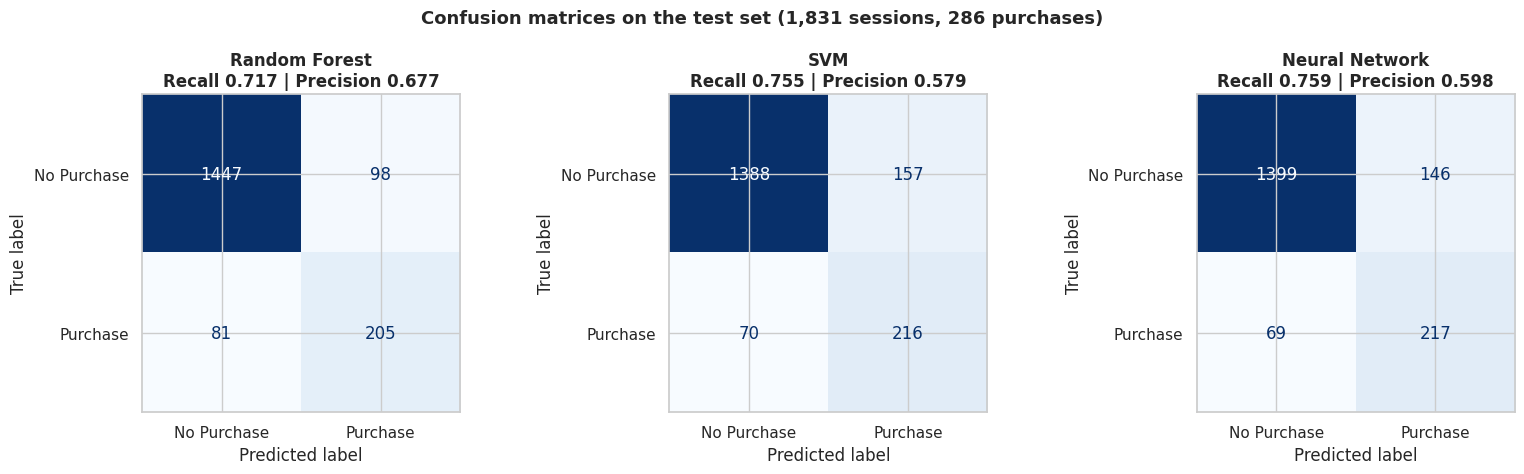

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, name in zip(axes, MODEL_NAMES):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[(name, "Test")], display_labels=["No Purchase", "Purchase"],
                                            cmap="Blues", colorbar=False, ax=ax, values_format="d")
    r = results[(name, "Test")]
    ax.set_title(f"{name}\nRecall {r['Recall']:.3f} | Precision {r['Precision']:.3f}", fontweight="bold")
fig.suptitle("Confusion matrices on the test set (1,831 sessions, 286 purchases)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{PLOTS}/fig15_test_confusion_matrices.png", dpi=300)
plt.show()

## 6. ROC and precision-recall curves

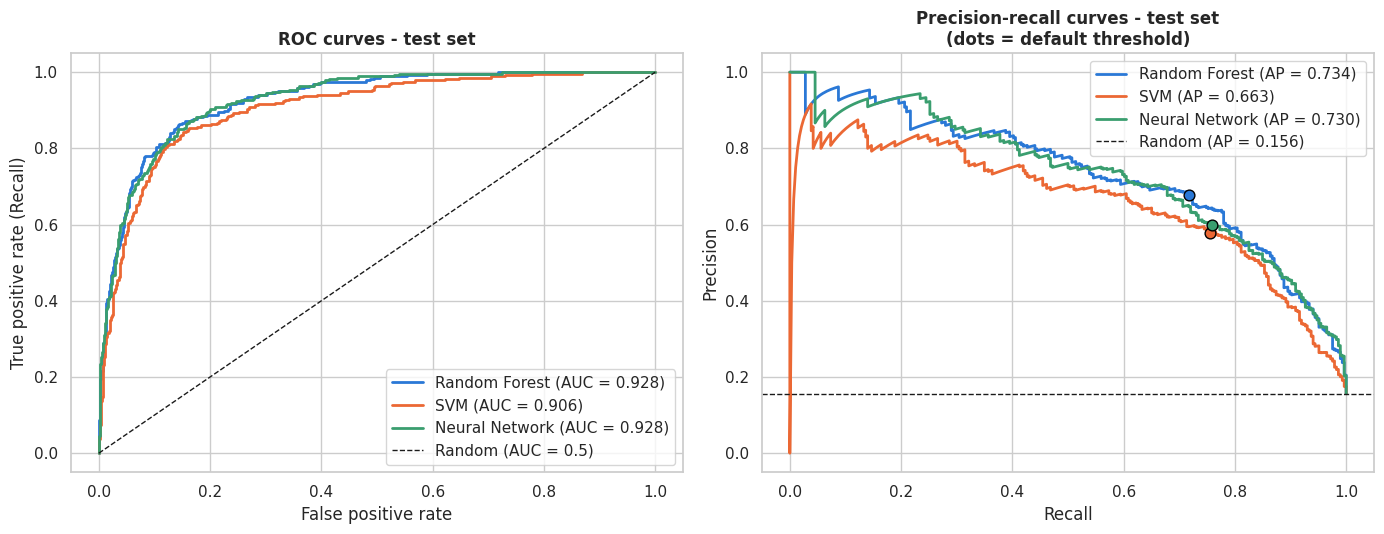

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
for name in MODEL_NAMES:
    s = scores[(name, "Test")]
    fpr, tpr, _ = roc_curve(y_test, s)
    ax1.plot(fpr, tpr, color=COLORS[name], lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, s):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, s)
    ax2.plot(rec, prec, color=COLORS[name], lw=2, label=f"{name} (AP = {average_precision_score(y_test, s):.3f})")
    r = results[(name, "Test")]
    ax2.scatter(r["Recall"], r["Precision"], color=COLORS[name], s=60, edgecolor="black", zorder=5)
ax1.plot([0, 1], [0, 1], "k--", lw=1, label="Random (AUC = 0.5)")
ax1.set_xlabel("False positive rate"); ax1.set_ylabel("True positive rate (Recall)")
ax1.set_title("ROC curves - test set", fontweight="bold"); ax1.legend(loc="lower right")
ax2.axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Random (AP = {y_test.mean():.3f})")
ax2.set_xlabel("Recall"); ax2.set_ylabel("Precision")
ax2.set_title("Precision-recall curves - test set\n(dots = default threshold)", fontweight="bold")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.savefig(f"{PLOTS}/fig16_test_roc_pr_curves.png", dpi=300)
plt.show()

## 7. Side-by-side metric comparison

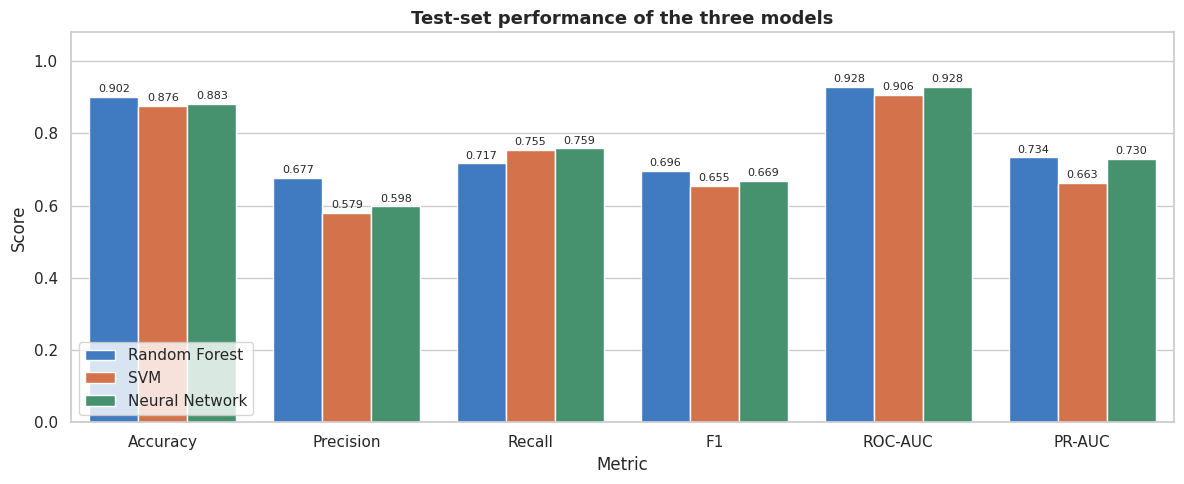

In [12]:
long = test_table.reset_index(names="Model").melt(id_vars="Model", var_name="Metric", value_name="Score")
plt.figure(figsize=(12, 5))
ax = sns.barplot(data=long, x="Metric", y="Score", hue="Model", palette=COLORS, hue_order=MODEL_NAMES)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
plt.ylim(0, 1.08)
plt.title("Test-set performance of the three models", fontsize=13, fontweight="bold")
plt.legend(loc="lower left")
plt.tight_layout()
plt.savefig(f"{PLOTS}/fig17_test_metric_comparison.png", dpi=300)
plt.show()

## 8. Are the differences real? (bootstrap and seed variability)

The test set has only 286 purchases, so small differences between models can be due to chance. Two checks:

1. **Bootstrap (1,000 resamples of the test set):** 95% confidence intervals for F1 and ROC-AUC, and for the *paired* difference between two models (both models are scored on the same resampled sessions). If the interval of a difference contains 0, the two models cannot be separated on this test set.
2. **Seed variability:** the Random Forest and the Neural Network depend on a random seed. Both are re-trained with 5 other seeds (same hyperparameters) to see how much the test score moves. The SVM is deterministic.

In [13]:
B = 1000
rng = np.random.RandomState(RANDOM_STATE)
n = len(y_test)
boot = {name: {"F1": [], "ROC-AUC": []} for name in MODEL_NAMES}
for _ in range(B):
    idx = rng.randint(0, n, n)
    yb = y_test[idx]
    for name in MODEL_NAMES:
        boot[name]["F1"].append(f1_score(yb, preds[(name, "Test")][idx]))
        boot[name]["ROC-AUC"].append(roc_auc_score(yb, scores[(name, "Test")][idx]))
boot = {name: {k: np.array(v) for k, v in d.items()} for name, d in boot.items()}

def ci(a):
    lo, hi = np.percentile(a, [2.5, 97.5])
    return f"[{lo:.4f}, {hi:.4f}]"

ci_table = pd.DataFrame({name: {"Test F1": round(float(results[(name, 'Test')]['F1']), 4),
                                "F1 95% CI": ci(boot[name]["F1"]),
                                "Test ROC-AUC": round(float(results[(name, 'Test')]['ROC-AUC']), 4),
                                "ROC-AUC 95% CI": ci(boot[name]["ROC-AUC"])} for name in MODEL_NAMES}).T
print("Bootstrap 95% confidence intervals (test set):")
print(ci_table.to_string())

pairs = [("Random Forest", "Neural Network"), ("Neural Network", "SVM"), ("Random Forest", "SVM")]
diff_rows = []
for a, b in pairs:
    for metric in ["F1", "ROC-AUC"]:
        d = boot[a][metric] - boot[b][metric]
        lo, hi = np.percentile(d, [2.5, 97.5])
        diff_rows.append({"Comparison": f"{a} - {b}", "Metric": metric,
                          "Observed difference": round(float(results[(a, 'Test')][metric] - results[(b, 'Test')][metric]), 4),
                          "95% CI": f"[{lo:.4f}, {hi:.4f}]",
                          f"Share of resamples where {a} is better": f"{100 * (d > 0).mean():.1f}%",
                          "Significant (CI excludes 0)": bool(lo > 0 or hi < 0)})
diff_table = pd.DataFrame(diff_rows)
print("\nPaired bootstrap differences:")
print(diff_table.to_string(index=False))

Bootstrap 95% confidence intervals (test set):
               Test F1         F1 95% CI Test ROC-AUC    ROC-AUC 95% CI
Random Forest   0.6961  [0.6502, 0.7348]       0.9279  [0.9129, 0.9423]
SVM             0.6555  [0.6101, 0.6966]        0.906  [0.8882, 0.9236]
Neural Network  0.6687  [0.6242, 0.7086]       0.9281  [0.9138, 0.9411]

Paired bootstrap differences:
                    Comparison  Metric  Observed difference            95% CI Share of resamples where Random Forest is better  Significant (CI excludes 0) Share of resamples where Neural Network is better
Random Forest - Neural Network      F1               0.0274 [-0.0036, 0.0552]                                            95.9%                        False                                               NaN
Random Forest - Neural Network ROC-AUC              -0.0002 [-0.0068, 0.0067]                                            49.0%                        False                                               NaN
          Neural

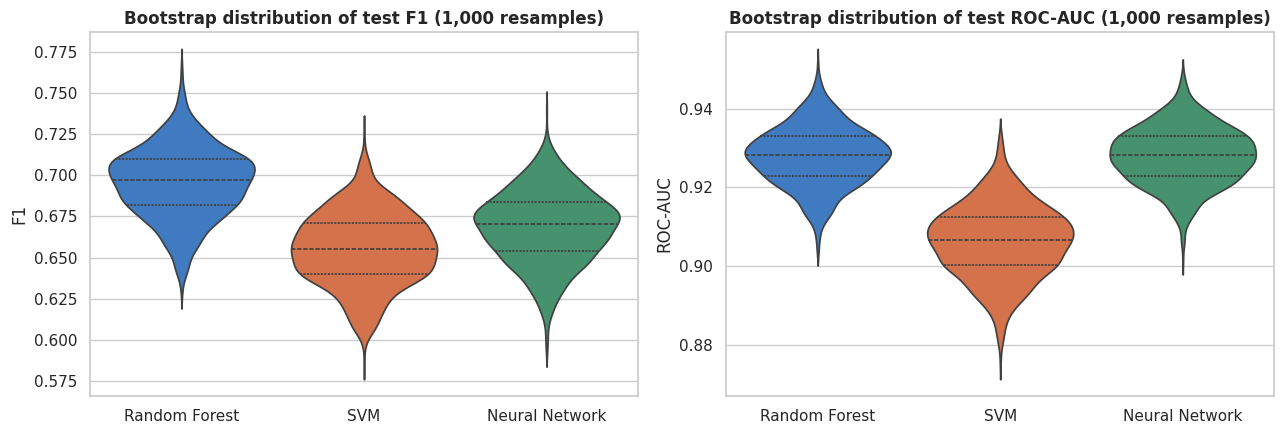

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric in zip(axes, ["F1", "ROC-AUC"]):
    data = pd.DataFrame({name: boot[name][metric] for name in MODEL_NAMES}).melt(var_name="Model", value_name=metric)
    sns.violinplot(data=data, x="Model", y=metric, hue="Model", palette=COLORS, order=MODEL_NAMES,
                   legend=False, inner="quartile", ax=ax)
    ax.set_title(f"Bootstrap distribution of test {metric} (1,000 resamples)", fontweight="bold")
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(f"{PLOTS}/fig18_test_bootstrap.png", dpi=300)
plt.show()

In [15]:
SEEDS = [200, 201, 202, 203, 204]
seed_rows = []
for seed in SEEDS:
    for name, model in [("Random Forest", make_rf(seed).fit(X_train, y_train)),
                        ("Neural Network", fit_nn(X_train, y_train, seed=seed, **NN_PARAMS))]:
        r = evaluate(y_test, get_preds(name, model, X_test), get_scores(name, model, X_test))
        seed_rows.append({"Model": name, "Seed": seed, "F1": r["F1"], "ROC-AUC": r["ROC-AUC"],
                          "Precision": r["Precision"], "Recall": r["Recall"]})
seed_df = pd.DataFrame(seed_rows)
seed_summary = seed_df.groupby("Model")[["F1", "ROC-AUC", "Precision", "Recall"]].agg(
    lambda s: f"{s.mean():.4f} ± {s.std():.4f}")
print("Test performance over 5 extra seeds (mean ± std):")
seed_summary

Test performance over 5 extra seeds (mean ± std):


,F1,ROC-AUC,Precision,Recall
Model,,,,
Neural Network,0.6730 ± 0.0051,0.9289 ± 0.0008,0.6048 ± 0.0187,0.7594 ± 0.0194
Random Forest,0.6876 ± 0.0043,0.9262 ± 0.0006,0.6643 ± 0.0050,0.7126 ± 0.0046


## 9. Generalisation: train vs validation vs test

If a model's test score is close to its validation score, the earlier model selection was not over-fitted to the validation set and the test estimate is trustworthy. The train - test gap shows how much each model overfits the training data.

In [16]:
gen = pd.DataFrame({split: res.xs(split, level="Set")["F1"].astype(float) for split in ["Train", "Validation", "Test"]})
gen.columns = [f"{c} F1" for c in gen.columns]
gen["Gap (train - test)"] = gen["Train F1"] - gen["Test F1"]
gen["Change (validation -> test)"] = gen["Test F1"] - gen["Validation F1"]
gen.loc[MODEL_NAMES].round(4)

,Train F1,Validation F1,Test F1,Gap (train - test),Change (validation -> test)
Model,,,,,
Random Forest,0.9286,0.6759,0.6961,0.2325,0.0202
SVM,0.6803,0.6331,0.6555,0.0248,0.0224
Neural Network,0.7103,0.6636,0.6687,0.0416,0.0052


## 10. Error analysis: which buyers are missed?

In [17]:
buyers = y_test == 1
found = pd.DataFrame({name: (preds[(name, "Test")] == 1) & buyers for name in MODEL_NAMES})
n_found = found.sum(axis=1)[buyers]
print(f"Buyers in the test set: {buyers.sum()}")
print(f"  found by all three models : {(n_found == 3).sum()}")
print(f"  found by one or two models: {((n_found > 0) & (n_found < 3)).sum()}")
print(f"  missed by all three models: {(n_found == 0).sum()}")

agree = np.mean([len({preds[(m, 'Test')][i] for m in MODEL_NAMES}) == 1 for i in range(len(y_test))])
print(f"\nAll three models give the same prediction for {100 * agree:.1f}% of the test sessions.")

missed_all = buyers & (found.sum(axis=1) == 0).values
found_all = buyers & (found.sum(axis=1) == 3).values
cols = ["PageValues", "ExitRates", "BounceRates", "ProductRelated", "ProductRelated_Duration"]
profile = pd.DataFrame({
    "Buyers found by all 3 (median)": X_test.loc[found_all, cols].median(),
    "Buyers missed by all 3 (median)": X_test.loc[missed_all, cols].median(),
    "Non-buyers (median)": X_test.loc[~buyers, cols].median()})
profile.loc["Share with PageValues = 0"] = [
    (X_test.loc[mask, "PageValues"] == 0).mean() for mask in (found_all, missed_all, ~buyers)]
profile.round(4)

Buyers in the test set: 286
  found by all three models : 190
  found by one or two models: 45
  missed by all three models: 51

All three models give the same prediction for 92.5% of the test sessions.


,Buyers found by all 3 (median),Buyers missed by all 3 (median),Non-buyers (median)
PageValues,27.8251,0.0000,0.0000
ExitRates,0.0134,0.0300,0.0282
BounceRates,0.0000,0.0023,0.0035
ProductRelated,24.0000,18.0000,16.0000
ProductRelated_Duration,993.2500,638.2500,497.3333
Share with PageValues = 0,0.0105,0.7843,0.8828


The table above shows what the hardest buyers look like. `PageValues` was the strongest feature in Stages 1 and 2, so buyers whose session has `PageValues = 0` look like ordinary non-buying sessions and are very hard for any model to detect.

## 11. Supplementary: tuning the decision threshold on the validation set

All results above use the default threshold, as in Stages 2 and 3. Because the classes are imbalanced, the default threshold is not necessarily the best one. As an extra analysis (it does **not** change the main comparison), the threshold that maximises F1 is chosen on the **validation** set and then applied once to the test set.

In [18]:
thr_rows = []
for name, m in models.items():
    p, r, t = precision_recall_curve(y_val, scores[(name, "Validation")])
    f1s = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    thr = t[np.argmax(f1s)]
    test_pred = (scores[(name, "Test")] >= thr).astype(int)
    thr_rows.append({"Model": name, "Default threshold": 0.0 if name == "SVM" else 0.5,
                     "Threshold tuned on validation": round(float(thr), 4),
                     "Test F1 (default)": round(float(results[(name, 'Test')]['F1']), 4),
                     "Test F1 (tuned)": round(f1_score(y_test, test_pred), 4),
                     "Test Precision (tuned)": round(precision_score(y_test, test_pred), 4),
                     "Test Recall (tuned)": round(recall_score(y_test, test_pred), 4)})
threshold_table = pd.DataFrame(thr_rows).set_index("Model")
threshold_table

,Default threshold,Threshold tuned on validation,Test F1 (default),Test F1 (tuned),Test Precision (tuned),Test Recall (tuned)
Model,,,,,,
Random Forest,0.5,0.3994,0.6961,0.6904,0.6194,0.7797
SVM,0.0,0.2519,0.6555,0.6562,0.5977,0.7273
Neural Network,0.5,0.4607,0.6687,0.6667,0.5862,0.7727


## 12. Save the results

In [19]:
comparison.to_csv(f"{DATA_DIR}/stage5_model_comparison.csv")
res.astype(float).round(4).to_csv(f"{DATA_DIR}/stage5_all_results.csv")
ci_table.to_csv(f"{DATA_DIR}/stage5_bootstrap_ci.csv")
diff_table.to_csv(f"{DATA_DIR}/stage5_bootstrap_differences.csv", index=False)
seed_df.to_csv(f"{DATA_DIR}/stage5_seed_variability.csv", index=False)
threshold_table.to_csv(f"{DATA_DIR}/stage5_threshold_analysis.csv")
print("Saved tables to", DATA_DIR)
print("Saved figures:", sorted(f for f in os.listdir(PLOTS) if f.startswith(("fig15", "fig16", "fig17", "fig18"))))

Saved tables to ./data
Saved figures: ['fig15_test_confusion_matrices.png', 'fig16_test_roc_pr_curves.png', 'fig17_test_metric_comparison.png', 'fig18_test_bootstrap.png']


## 13. Final model selection

In [20]:
best_f1 = test_table["F1"].idxmax()
best_auc = test_table["ROC-AUC"].idxmax()
best_recall = test_table["Recall"].idxmax()
best_precision = test_table["Precision"].idxmax()
print(f"Highest test F1       : {best_f1} ({test_table.loc[best_f1, 'F1']:.4f})")
print(f"Highest test ROC-AUC  : {best_auc} ({test_table.loc[best_auc, 'ROC-AUC']:.4f})")
print(f"Highest test Recall   : {best_recall} ({test_table.loc[best_recall, 'Recall']:.4f})")
print(f"Highest test Precision: {best_precision} ({test_table.loc[best_precision, 'Precision']:.4f})")
print("\nSignificant differences (paired bootstrap, 95%):")
sig = diff_table[diff_table["Significant (CI excludes 0)"]]
print(sig[["Comparison", "Metric", "Observed difference", "95% CI"]].to_string(index=False) if len(sig) else "  none")

Highest test F1       : Random Forest (0.6961)
Highest test ROC-AUC  : Neural Network (0.9281)
Highest test Recall   : Neural Network (0.7587)
Highest test Precision: Random Forest (0.6766)

Significant differences (paired bootstrap, 95%):
          Comparison  Metric  Observed difference           95% CI
Neural Network - SVM ROC-AUC               0.0220 [0.0131, 0.0304]
 Random Forest - SVM      F1               0.0406 [0.0089, 0.0702]
 Random Forest - SVM ROC-AUC               0.0218 [0.0112, 0.0321]


## 14. Summary

* All three models were re-fitted on the training set with the hyperparameters selected in Stages 2 and 3 and evaluated **once** on the untouched test set (1,831 sessions, 286 purchases).
* The main metric is F1 on the purchase class, supported by ROC-AUC, PR-AUC and the confusion matrix, because accuracy is misleading with an 84 / 16 class imbalance.
* The comparison table, the bootstrap confidence intervals and the seed analysis are the basis for the **Discussion** and **Conclusion** of the report: which model is most suitable, whether the Neural Network beats the traditional models, and the trade-off between missed buyers (Recall) and false alarms (Precision).
* Figures: `fig15` confusion matrices, `fig16` ROC and precision-recall curves, `fig17` metric comparison, `fig18` bootstrap distributions.